# Analyse des accidents routiers en Australie-Méridionale avec PySpark

## 1-Démarrer PySpark

In [1]:
import sys
import pyspark
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

print("Python :", sys.executable)
print("PySpark :", pyspark.__version__)

spark = SparkSession.builder.master("local[2]").appName("RoadCrashEtude").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark prêt !")

Python : /bin/python
PySpark : 3.5.7


26/10/16 09:48:23 WARN Utils: Your hostname, LAPTOP-C314Q5B1 resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/16 09:48:23 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 09:48:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/16 09:48:27 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark prêt !


## 2- Charger les données

- *Crashes* : une ligne par accident ; lieu, gravité, victimes.
- *Units* : les unités/véhicules impliqués ; informations sur les conducteurs et les permis.

La jointure se fera sur `REPORT_ID`. On vérifie d'abord les volumes et les colonnes disponibles.

In [2]:
dossier = Path.cwd()
assert (dossier / "crash_data").is_dir(), "Dossier crash_data introuvable : place ce notebook à la racine du projet."
assert (dossier / "units_data").is_dir(), "Dossier units_data introuvable : place ce notebook à la racine du projet."

crash_df = spark.read.option("header", True).option("escape", '"').csv(str(dossier / "crash_data" / "*.csv"))
units_df = spark.read.option("header", True).option("escape", '"').csv(str(dossier / "units_data" / "*.csv"))

print("Accidents :", crash_df.count())
print("Unités    :", units_df.count())
print("Colonnes Crashes :", crash_df.columns)
print("Colonnes Units   :", units_df.columns)
crash_df.select("REPORT_ID", "Suburb", "Crash Type", "CSEF Severity").show(5, truncate=False)

Accidents : 127672
Unités    : 272591
Colonnes Crashes : ['REPORT_ID', 'Stats Area', 'Suburb', 'Postcode', 'LGA Name', 'Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI', 'Year', 'Month', 'Day', 'Time', 'Area Speed', 'Position Type', 'Horizontal Align', 'Vertical Align', 'Other Feat', 'Road Surface', 'Moisture Cond', 'Weather Cond', 'DayNight', 'Crash Type', 'Unit Resp', 'Entity Code', 'CSEF Severity', 'Traffic Ctrls', 'DUI Involved', 'Drugs Involved', 'ACCLOC_X', 'ACCLOC_Y', 'UNIQUE_LOC']
Colonnes Units   : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']
+-----------------+--------------+------------------+-------------+
|REPORT_ID        |Suburb        |Crash Type        |CSEF Severity|
+-----------------+--------------+------------------+-------------+
|2012-1-21/08/2019|STEPNEY

## 3- Nettoyage et contrôles

On transforme seulement les colonnes numériques nécessaires. Les valeurs manquantes ou non numériques de `Age` deviennent nulles. Ensuite, on contrôle l'unicité des identifiants d'accidents : un même `REPORT_ID` ne devrait représenter qu'un accident.

In [3]:
crash_df = (crash_df
    .withColumn("Total Cas", F.col("Total Cas").cast("int"))
    .withColumn("Total Fats", F.col("Total Fats").cast("int"))
    .withColumn("Year", F.col("Year").cast("int")))

units_df = units_df.withColumn("Age_num", F.col("Age").cast("int"))

n_crash = crash_df.count()
n_uniques = crash_df.select("REPORT_ID").distinct().count()
print("Accidents :", n_crash, "| Identifiants distincts :", n_uniques)
print("Âges exploitables :", units_df.filter(F.col("Age_num").between(0, 110)).count())
assert n_crash == n_uniques, "Attention : REPORT_ID n'est pas unique dans Crashes. Examiner les doublons."
assert n_crash > 0, "Aucun accident chargé."

Accidents : 127672 | Identifiants distincts : 127672


Âges exploitables : 217557


## 4- Analyse RDD

Un **RDD** est une collection de données distribuée entre plusieurs partitions. Nous l'utilisons pour calculer l'âge moyen selon le sexe, puis pour séparer les unités immatriculées en Australie-Méridionale (`SA`) des autres.

On applique `reduceByKey` plutôt que `groupByKey` : seules les sommes et les effectifs sont nécessaires.

In [4]:
age_rdd = (units_df
    .filter(F.col("Age_num").between(0, 110) & F.col("Sex").isin("Male", "Female"))
    .select("Sex", "Age_num").rdd
    .map(lambda r: (r[0], (r[1], 1))))

age_total = age_rdd.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
ages_rdd = dict(age_total.mapValues(lambda v: round(v[0] / v[1], 2)).collect())
print("Âge moyen par sexe (RDD) :", ages_rdd)

etat_rdd = units_df.select("Lic State").rdd.map(lambda r: (r[0], 1))
partitions = etat_rdd.partitionBy(2, lambda etat: 0 if etat == "SA" else 1)
comptages = partitions.mapPartitionsWithIndex(
    lambda i, it: [(i, sum(1 for _ in it))]
).collect()
print("Partition 0 = SA ; partition 1 = autres :", comptages)

Âge moyen par sexe (RDD) : {'Male': 40.8, 'Female': 40.08}


Partition 0 = SA ; partition 1 = autres : [(0, 198646), (1, 73945)]


## 5- Refaire une analyse avec les DataFrames

Les **DataFrames** permettent de manipuler les colonnes par leur nom. On retrouve ici l'âge moyen obtenu avec les RDD, puis on examine la fréquence et la gravité des accidents.

In [5]:
ages_df = (units_df
    .filter(F.col("Age_num").between(0, 110) & F.col("Sex").isin("Male", "Female"))
    .groupBy("Sex").agg(F.round(F.avg("Age_num"), 2).alias("Age moyen")))
ages_df.show()

# Vérification RDD / DataFrame
ages_verif = {r["Sex"]: r["Age moyen"] for r in ages_df.collect()}
assert ages_rdd == ages_verif, "Les résultats RDD et DataFrame ne concordent pas."
print("Vérification RDD = DataFrame : OK")

+------+---------+
|   Sex|Age moyen|
+------+---------+
|Female|    40.08|
|  Male|     40.8|
+------+---------+



Vérification RDD = DataFrame : OK


### 5-1 Nombre d'accidents par année et par gravité

On travaille sur les accidents, et non sur le nombre de véhicules. Les pourcentages sont calculés sur le total d'accidents.

In [6]:
accidents_an = crash_df.groupBy("Year").count().orderBy("Year")
accidents_an.show(10)

severite_df = (crash_df.groupBy("CSEF Severity").count()
    .withColumn("Pourcentage", F.round(F.col("count") * 100 / n_crash, 2))
    .orderBy("CSEF Severity"))
severite_df.show(truncate=False)

+----+-----+
|Year|count|
+----+-----+
|2012|22829|
|2013|16675|
|2014|16162|
|2015|15431|
|2016|16775|
|2017|13237|
|2018|13599|
|2019|12964|
+----+-----+



+-------------+-----+-----------+
|CSEF Severity|count|Pourcentage|
+-------------+-----+-----------+
|1: PDO       |84775|66.4       |
|2: MI        |37300|29.22      |
|3: SI        |4875 |3.82       |
|4: Fatal     |722  |0.57       |
+-------------+-----+-----------+



### 5-2 Accidents avec le plus de victimes et types les plus mortels

`Total Cas` compte les victimes (blessés ou morts selon les catégories du jeu de données) et `Total Fats` compte les décès. Il ne faut pas confondre le nombre de décès avec le nombre d'accidents mortels.

In [7]:
print("10 accidents avec le plus de victimes :")
crash_df.select("REPORT_ID", "Suburb", "Total Cas", "CSEF Severity") \
    .orderBy(F.desc("Total Cas")).show(10, truncate=False)

print("Nombre de décès par type d'accident :")
morts_type_df = (crash_df.groupBy("Crash Type")
    .agg(F.sum("Total Fats").alias("Deces"))
    .orderBy(F.desc("Deces")))
morts_type_df.show(15, truncate=False)

print("Accidents à ADELAIDE avec plus de 3 victimes :")
crash_df.filter((F.col("Suburb") == "ADELAIDE") & (F.col("Total Cas") > 3)) \
    .select("REPORT_ID", "Suburb", "Total Cas").show(10, truncate=False)

10 accidents avec le plus de victimes :


+---------------------+-------------+---------+-------------+
|REPORT_ID            |Suburb       |Total Cas|CSEF Severity|
+---------------------+-------------+---------+-------------+
|2017-288-15/08/2019  |PARA HILLS   |11       |3: SI        |
|2016-3035-15/08/2019 |HACKHAM      |9        |4: Fatal     |
|2019-11734-8/07/2020 |STURT        |9        |3: SI        |
|2016-6630-15/08/2019 |KANGAROO FLAT|9        |3: SI        |
|2014-9004-21/08/2019 |APY          |9        |4: Fatal     |
|2014-14065-21/08/2019|MODBURY NORTH|9        |2: MI        |
|2015-2823-21/08/2019 |HAWKER       |8        |2: MI        |
|2012-890-21/08/2019  |KULPARA      |8        |4: Fatal     |
|2016-7073-15/08/2019 |MERRITON     |8        |4: Fatal     |
|2016-14407-15/08/2019|STOCKWELL    |8        |4: Fatal     |
+---------------------+-------------+---------+-------------+
only showing top 10 rows

Nombre de décès par type d'accident :


+--------------------------+-----+
|Crash Type                |Deces|
+--------------------------+-----+
|Hit Fixed Object          |245  |
|Head On                   |136  |
|Hit Pedestrian            |109  |
|Roll Over                 |93   |
|Right Angle               |82   |
|Rear End                  |33   |
|Side Swipe                |30   |
|Right Turn                |26   |
|Hit Parked Vehicle        |10   |
|Hit Animal                |7    |
|Other                     |5    |
|Left Road - Out of Control|3    |
|Hit Object on Road        |2    |
+--------------------------+-----+

Accidents à ADELAIDE avec plus de 3 victimes :


+---------------------+--------+---------+
|REPORT_ID            |Suburb  |Total Cas|
+---------------------+--------+---------+
|2012-4842-21/08/2019 |ADELAIDE|4        |
|2012-5769-21/08/2019 |ADELAIDE|4        |
|2018-601-17/01/2020  |ADELAIDE|4        |
|2017-1613-15/08/2019 |ADELAIDE|4        |
|2017-12182-15/08/2019|ADELAIDE|5        |
|2019-10404-8/07/2020 |ADELAIDE|6        |
+---------------------+--------+---------+



### 5-3 Accidents impliquant un conducteur sans permis

On joint `Crashes` et `Units` par `REPORT_ID`. Pour ne pas compter deux fois les victimes d'un accident impliquant plusieurs conducteurs sans permis, nous récupérons d'abord les identifiants distincts des accidents concernés.

In [8]:
sans_permis = (units_df
    .filter(F.col("Licence Type") == "Unlicenced")
    .select("REPORT_ID").distinct())

accidents_sans_permis = crash_df.join(sans_permis, "REPORT_ID", "inner")
par_quartier = (accidents_sans_permis.groupBy("Suburb")
    .agg(F.count("REPORT_ID").alias("Accidents"),
         F.sum("Total Cas").alias("Victimes"))
    .orderBy(F.desc("Victimes")))
par_quartier.show(10, truncate=False)

+--------------+---------+--------+
|Suburb        |Accidents|Victimes|
+--------------+---------+--------+
|ADELAIDE      |149      |42      |
|SALISBURY     |40       |30      |
|PROSPECT      |48       |27      |
|INGLE FARM    |32       |22      |
|MORPHETT VALE |49       |20      |
|DRY CREEK     |19       |19      |
|SALISBURY EAST|30       |19      |
|MURRAY BRIDGE |30       |19      |
|NORTH ADELAIDE|42       |17      |
|MAWSON LAKES  |36       |17      |
+--------------+---------+--------+
only showing top 10 rows



## 6- Alcool, drogues et gravité

Nous comparons quatre groupes qui ne se recouvrent pas : les deux signalés, alcool seul signalé, drogues seules signalées, aucun des deux signalé.

Aussi « non signalé » ne signifie pas nécessairement « testé négatif ». Ces résultats montrent des associations descriptives, pas une relation de cause à effet.

In [9]:
alcool = F.col("DUI Involved") == "Y"
drogues = F.col("Drugs Involved") == "Y"

crash_expo = crash_df.withColumn(
    "Groupe",
    F.when(alcool & drogues, "Alcool + drogues")
     .when(alcool, "Alcool signalé seul")
     .when(drogues, "Drogues signalées seules")
     .otherwise("Aucun des deux signalé")
)

comparaison = (crash_expo.groupBy("Groupe", "CSEF Severity").count()
    .withColumn("Pourcentage", F.round(
        F.col("count") * 100 / F.sum("count").over(Window.partitionBy("Groupe")), 2))
    .orderBy("Groupe", "CSEF Severity"))
comparaison.show(30, truncate=False)

+------------------------+-------------+-----+-----------+
|Groupe                  |CSEF Severity|count|Pourcentage|
+------------------------+-------------+-----+-----------+
|Alcool + drogues        |1: PDO       |36   |12.08      |
|Alcool + drogues        |2: MI        |151  |50.67      |
|Alcool + drogues        |3: SI        |72   |24.16      |
|Alcool + drogues        |4: Fatal     |39   |13.09      |
|Alcool signalé seul     |1: PDO       |2108 |57.27      |
|Alcool signalé seul     |2: MI        |1092 |29.67      |
|Alcool signalé seul     |3: SI        |384  |10.43      |
|Alcool signalé seul     |4: Fatal     |97   |2.64       |
|Aucun des deux signalé  |1: PDO       |82430|67.49      |
|Aucun des deux signalé  |2: MI        |35099|28.74      |
|Aucun des deux signalé  |3: SI        |4100 |3.36       |
|Aucun des deux signalé  |4: Fatal     |508  |0.42       |
|Drogues signalées seules|1: PDO       |201  |12.92      |
|Drogues signalées seules|2: MI        |958  |61.57     

## 7- Graphiques

On ne convertit en Pandas que les petits tableaux déjà agrégés, jamais les centaines de milliers de lignes d'origine.

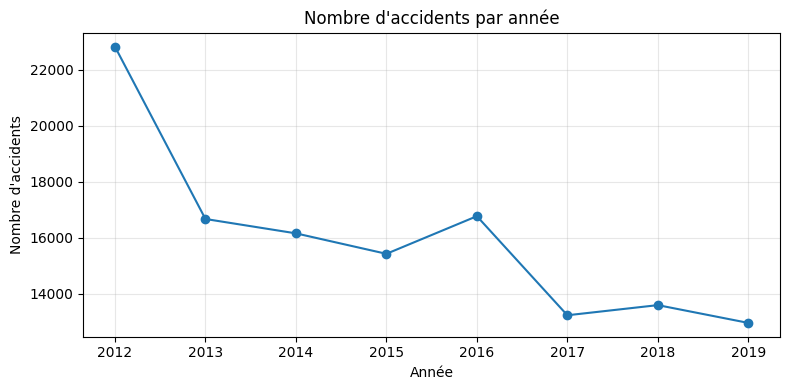

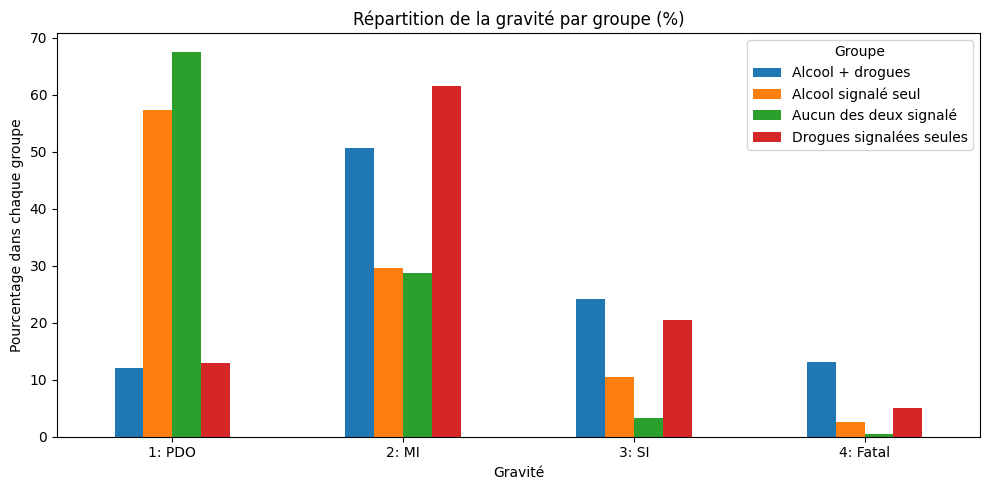

In [10]:
annuel_pd = accidents_an.toPandas()
plt.figure(figsize=(8, 4))
plt.plot(annuel_pd["Year"], annuel_pd["count"], marker="o")
plt.title("Nombre d'accidents par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'accidents")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

comp_pd = comparaison.toPandas()
comp_table = comp_pd.pivot(index="CSEF Severity", columns="Groupe", values="Pourcentage")
comp_table = comp_table.reindex(sorted(comp_table.index))
comp_table.plot(kind="bar", figsize=(10, 5))
plt.title("Répartition de la gravité par groupe (%)")
plt.xlabel("Gravité")
plt.ylabel("Pourcentage dans chaque groupe")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8- Retrouver le résultat avec SparkSQL

Le but n'est pas de multiplier les requêtes mais de montrer qu'une même question peut être traitée de deux façons. Nous comparons la somme des décès par type d'accident obtenue avec les DataFrames et avec une requête SQL.

In [11]:
crash_df.createOrReplaceTempView("crashes")

morts_sql = spark.sql("""
    SELECT `Crash Type`, SUM(`Total Fats`) AS Deces
    FROM crashes
    GROUP BY `Crash Type`
    ORDER BY Deces DESC
""")
morts_sql.show(15, truncate=False)

# Comparaison des résultats (sans dépendre de l'ordre des lignes)
resultat_df = {r["Crash Type"]: r["Deces"] for r in morts_type_df.collect()}
resultat_sql = {r["Crash Type"]: r["Deces"] for r in morts_sql.collect()}
assert resultat_df == resultat_sql, "Différence entre DataFrame et SQL."
print("Vérification DataFrame = SQL : OK")

+--------------------------+-----+
|Crash Type                |Deces|
+--------------------------+-----+
|Hit Fixed Object          |245  |
|Head On                   |136  |
|Hit Pedestrian            |109  |
|Roll Over                 |93   |
|Right Angle               |82   |
|Rear End                  |33   |
|Side Swipe                |30   |
|Right Turn                |26   |
|Hit Parked Vehicle        |10   |
|Hit Animal                |7    |
|Other                     |5    |
|Left Road - Out of Control|3    |
|Hit Object on Road        |2    |
+--------------------------+-----+



Vérification DataFrame = SQL : OK


## 9 - Bilan de l'étude

L'année 2012 enregistre le plus grand nombre d'accidents, avec environ 22 800 cas. Globalement, on observe une diminution entre 2012 et 2019, malgré quelques augmentations, notamment en 2016.

Dans l'étude de référence, les accidents contre un objet fixe, les collisions frontales et les accidents impliquant des piétons sont ceux qui entraînent le plus de décès.

Concernant la gravité, les accidents sans alcool ni drogues signalés sont majoritairement des accidents avec des dégâts matériels. En revanche, la proportion d'accidents graves ou mortels est nettement plus élevée lorsque l'alcool et les drogues sont signalés ensemble.

J'ai trouvé les DataFrames plus faciles à utiliser pour les analyses, notamment avec `filter`, `groupBy` et `join`. Les RDD permettent de mieux comprendre le fonctionnement de Spark, tandis que SparkSQL est pratique pour écrire directement des requêtes SQL.

### Limites

Cette analyse concerne uniquement l'Australie-Méridionale entre 2012 et 2019. Les résultats montrent des associations, mais ne permettent pas d'affirmer que l'alcool ou les drogues sont directement responsables de la gravité des accidents. De plus, l'absence de signalement ne signifie pas forcément un test négatif.